# PoLaRiS Demo Notebook

Walks through the full pipeline, one step at a time, on your own FITS tile(s). Assumes SExtractor, the Python environment, and `input/FITS_images/` + `input/sextractor/` are already set up — this notebook just calls each step's function in order.

## Setup

Point `config.TILE_NAMES` at your tile(s) and set plots to render inline instead of saving to disk.

In [4]:
from polaris import config
from polaris.helpers import setup_plot_mode

config.TILE_NAMES = ["KIDS_9.3_-31.2"]  # replace with your tile name(s)

setup_plot_mode(show=True)  # render plots inline in this notebook

True

## Step 2: Data Preprocessing

Preview the raw tile(s).

Found 1 tiles:
  KIDS_9.3_-31.2.fits


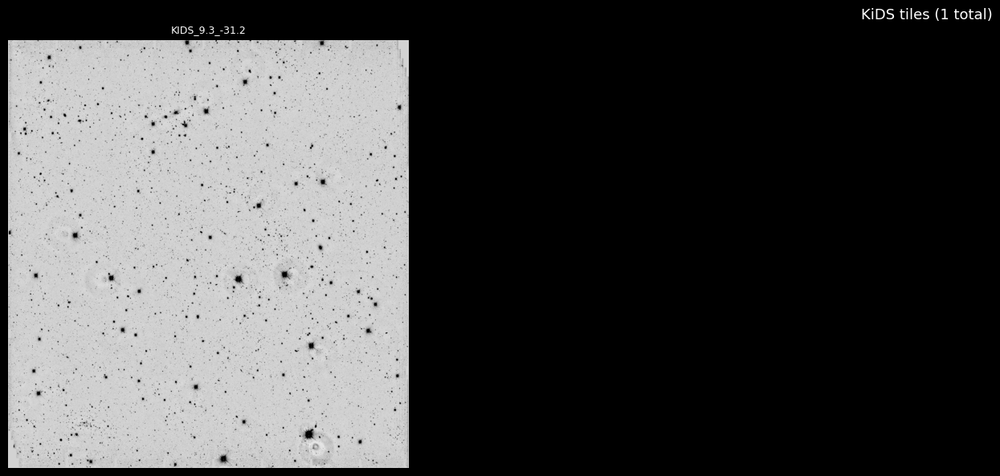

In [5]:
from polaris.preprocessing import inspect_raw_fits

inspect_raw_fits()

## Step 3: SExtractor Setup and Run

Run source detection, then preview the segmentation maps.


[1/1] KIDS_9.3_-31.2
  SEEING=0.8460"  SATUR=9.516e-08  PIXSCALE=0.2000"/px
  ✓ Done — 54023 detections, 5020 stars (CLASS_STAR≥0.84)

SExtractor ran for all 1 FITS files.
Found 1 segmaps:
  segmap_KIDS_9.3_-31.2.fits


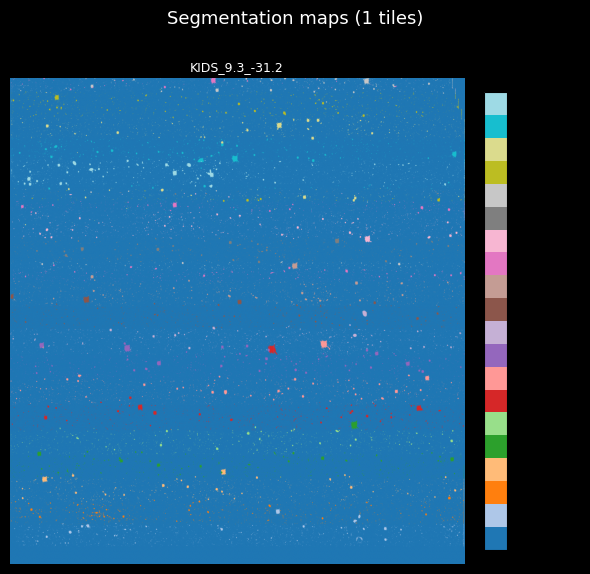

In [6]:
from polaris.run_sextractor import run_sextractor_on_tiles, preview_segmaps

run_sextractor_on_tiles()
preview_segmaps()

## Step 4: Background Subtraction

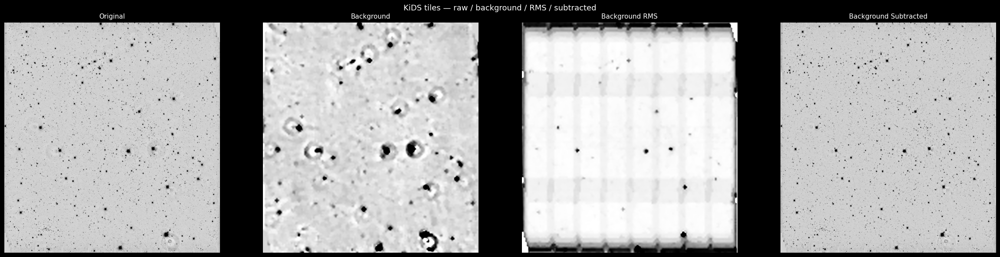

In [7]:
from polaris.background import plot_background_subtraction

plot_background_subtraction()

## Step 5: Point Source Identification

KIDS_9.3_-31.2: 5020 point sources


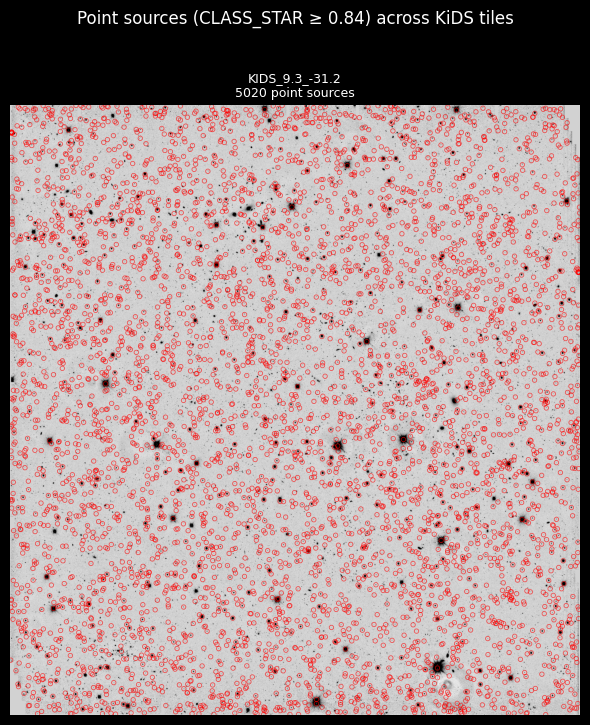

KIDS_9.3_-31.2: 54023 sources, 5320 point sources (CS≥0.805)


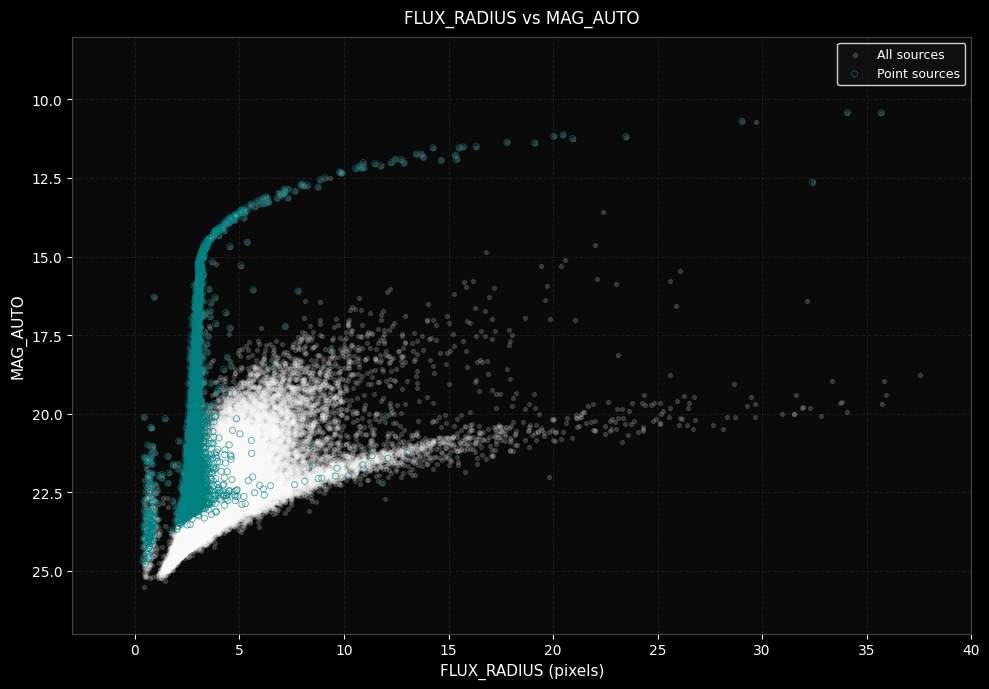

In [8]:
from polaris.point_sources import plot_point_sources, flux_radius_vs_mag

plot_point_sources()
catalog_all, stars_all = flux_radius_vs_mag()

## Step 6: Gaia Validation

Cross-matches against Gaia DR3 and writes `master.csv`.


==================================================  KIDS_9.3_-31.2
  PSF sources (CLASS_STAR≥0.84, FLAGS≤7): 5014
  Outer_2 SE-only: 5
  Gaia (cached): 3206
  Match threshold: 0.744"
  Gaia-matched: 2632
  Core            16–21: 2222
  Intermediate    14–16:  214
  Outer_1         11–14:   77
  Outer_2         8–11:    5 (SE-only)
Saved: /home/rabbit/PoLaRiS/output/gaia_validation/KIDS_9.3_-31.2.csv  (2627 stars)

Total: 2627 stars across 1 tiles
  Core            16–21:  2222
  Intermediate    14–16:   214
  Outer_1         11–14:    77
  Outer_2         8–11:     5 (SE-only)


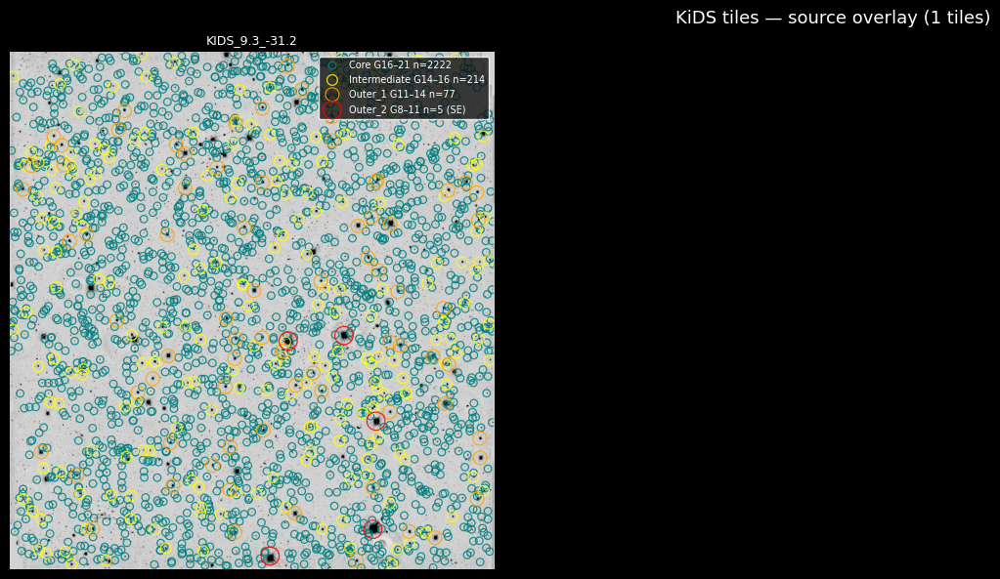

In [9]:
from polaris.gaia_validation import build_master_catalog, plot_source_overlay

combined, all_matched = build_master_catalog()
plot_source_overlay(all_matched)

## Step 7: Star Selection

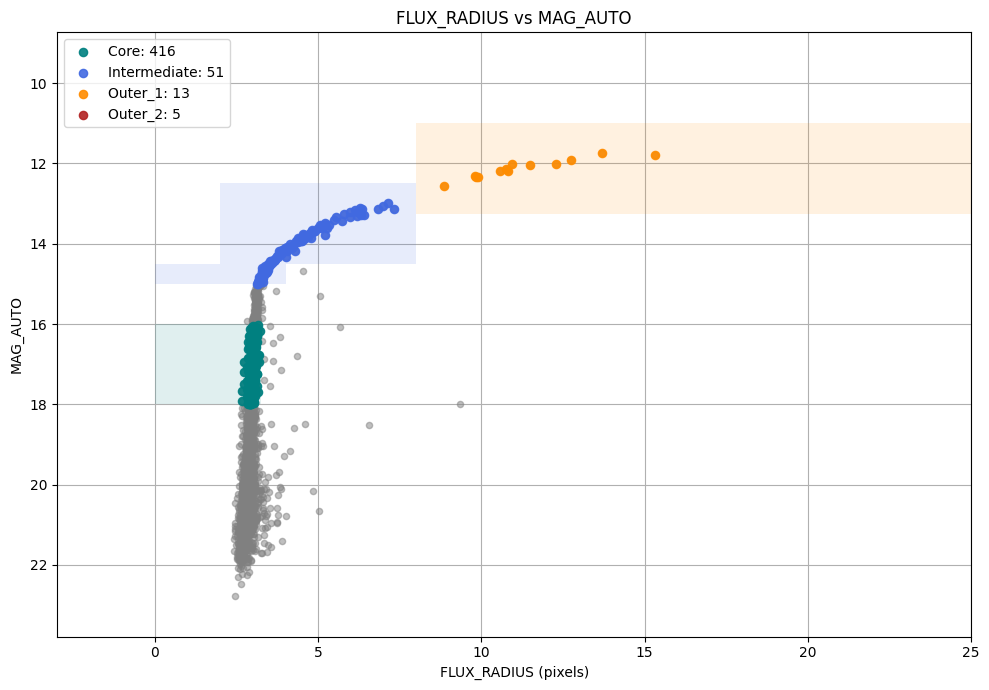

In [10]:
from polaris.star_selection import plot_star_selection

plot_star_selection()

## Step 8: Cutout Generation

KIDS_9.3_-31.2: saved=602  skipped=11

Total: saved=602  skipped=11


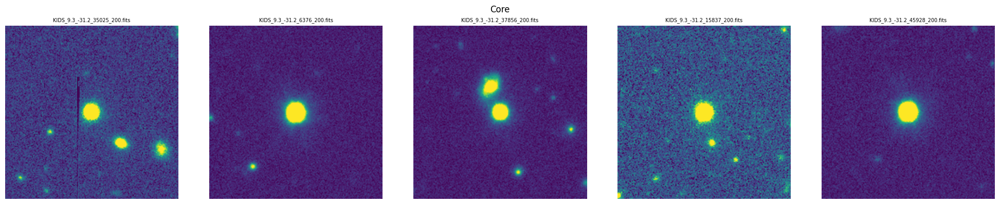

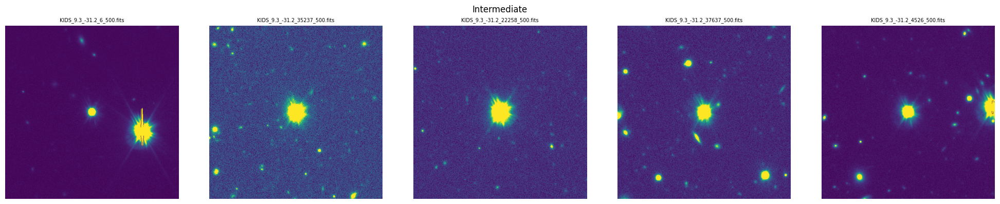

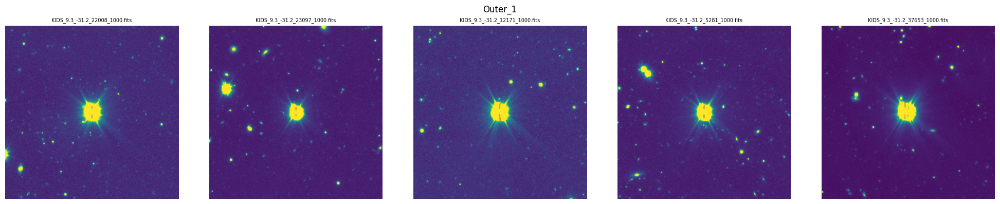

In [11]:
from polaris.cutouts import generate_cutouts, preview_cutouts

generate_cutouts()
preview_cutouts()

## Step 9: Masking

Core: 450 accepted
Intermediate: 140 accepted
Outer_1: 12 accepted
Outer_2: 0 accepted


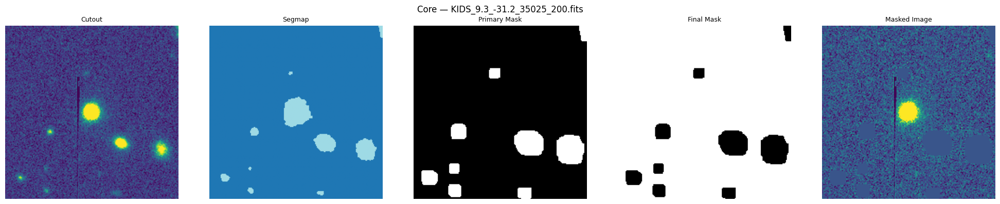

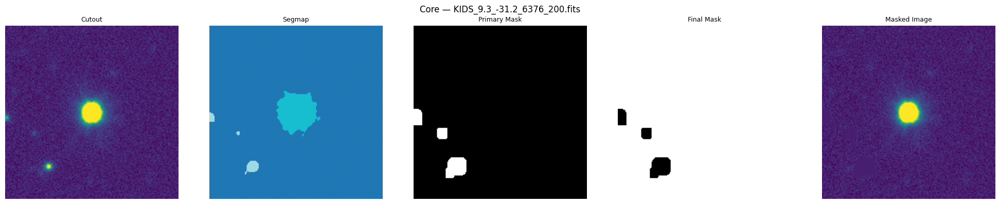

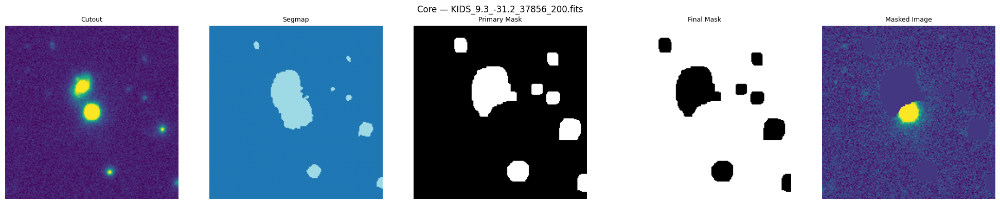

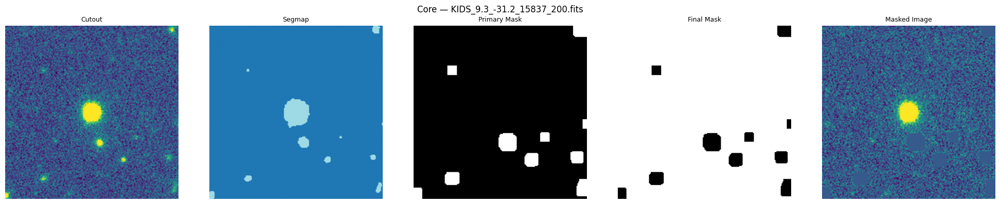

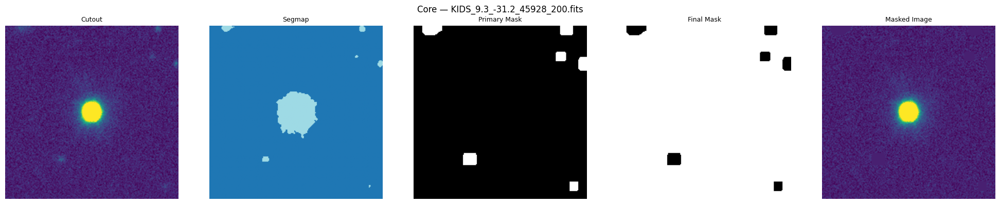

...

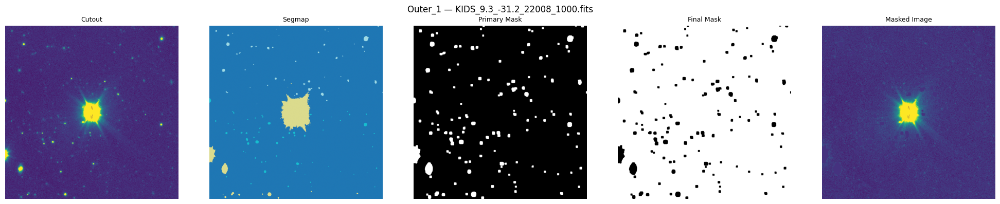

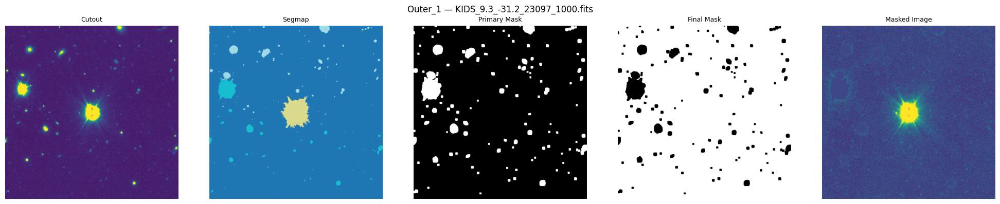

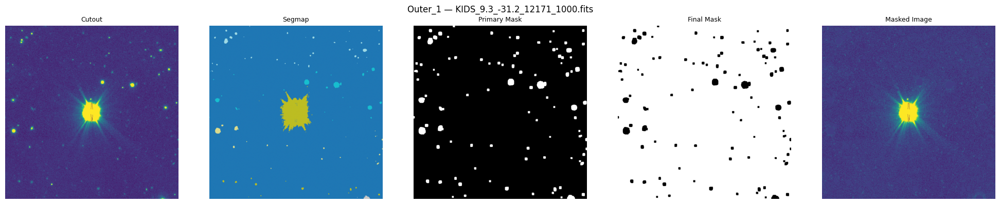

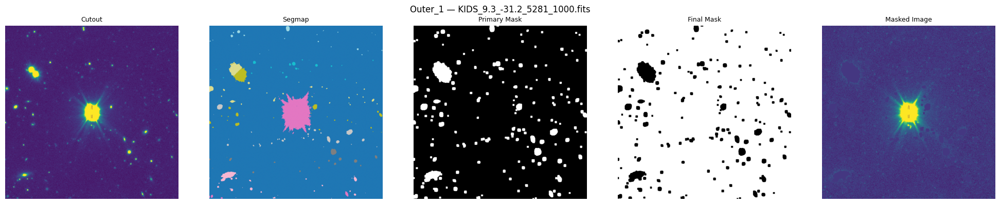

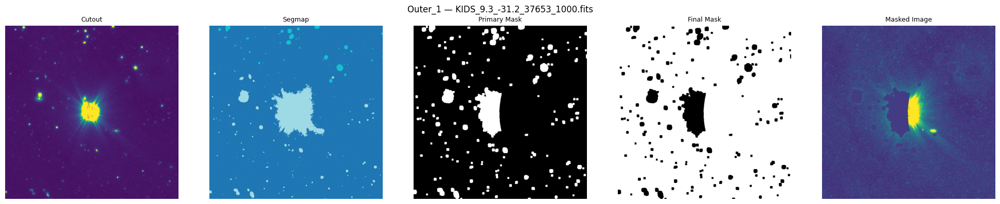

In [12]:
from polaris.masking import build_masks, preview_masking

build_masks()
preview_masking()

## Step 10: Stacking

/home/rabbit/PoLaRiS/polaris/stacking.py:114: RuntimeWarning: All-NaN slice encountered
  median_stack = np.nanmedian(stack_array, axis=0)
/home/rabbit/PoLaRiS/polaris/stacking.py:115: RuntimeWarning: Mean of empty slice
  mean_stack = np.nanmean(stack_array, axis=0)
/home/rabbit/miniforge3/envs/psf/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1594: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


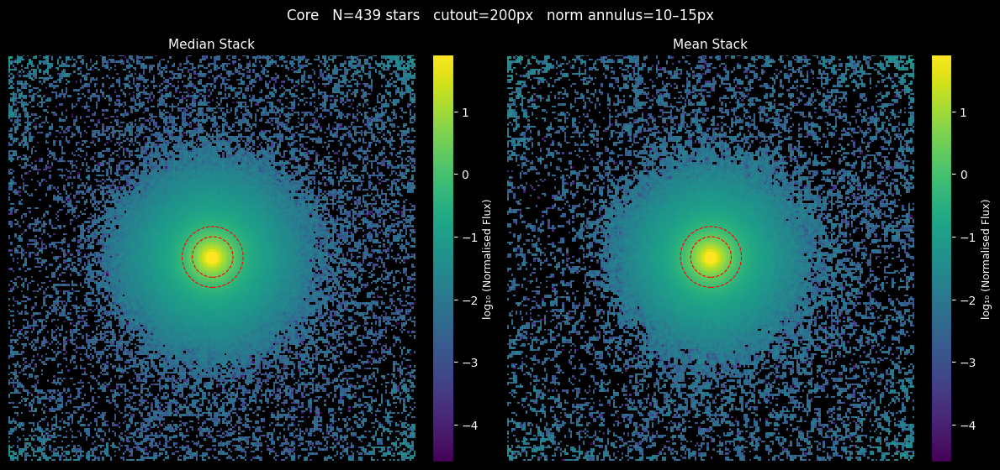

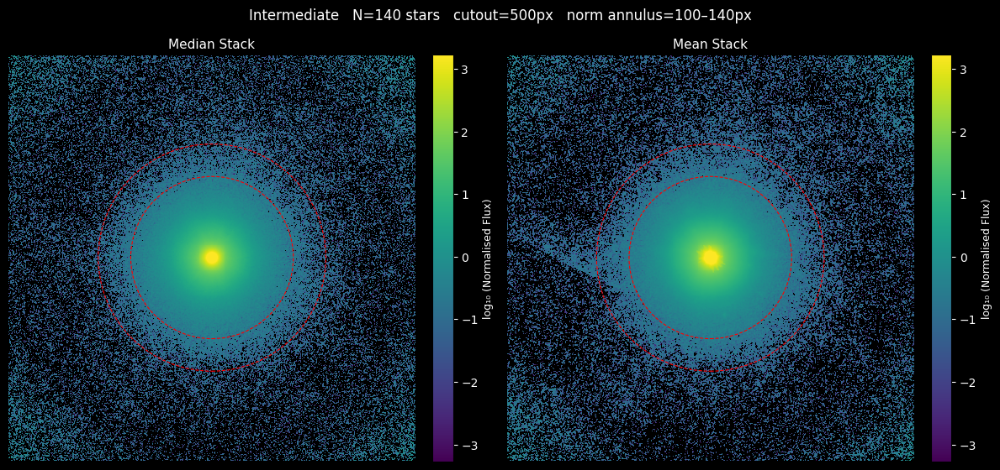

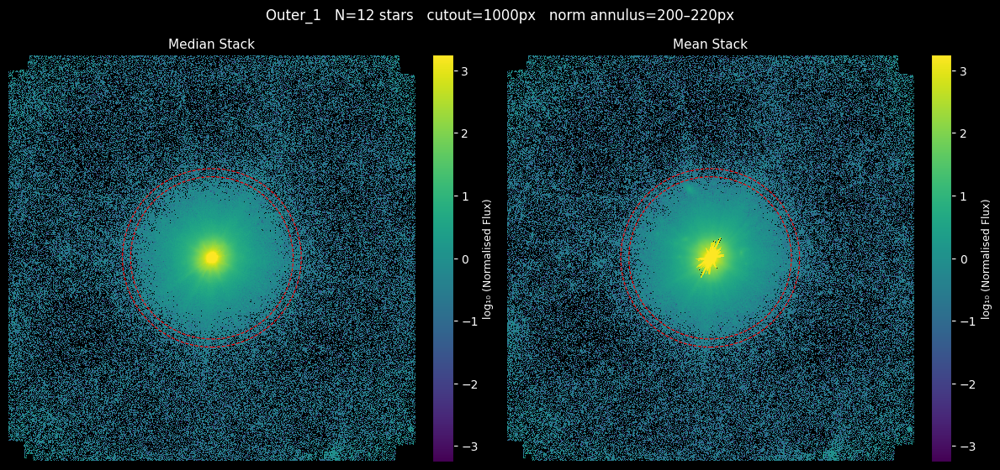

[SKIP] Outer_2: no valid PSFs — check summary below

       Stack  Total  Accepted  Rej_shape  Rej_valid  Rej_masked  Rej_centre  Rej_norm
        Core    450       439          0          0          11           0         0
Intermediate    140       140          0          0           0           0         0
     Outer_1     12        12          0          0           0           0         0
     Outer_2      0         0          0          0           0           0         0


[{'Stack': 'Core',
  'Total': 450,
  'Accepted': 439,
  'Rej_shape': 0,
  'Rej_valid': 0,
  'Rej_masked': 11,
  'Rej_centre': 0,
  'Rej_norm': 0},
 {'Stack': 'Intermediate',
  'Total': 140,
  'Accepted': 140,
  'Rej_shape': 0,
  'Rej_valid': 0,
  'Rej_masked': 0,
  'Rej_centre': 0,
  'Rej_norm': 0},
 {'Stack': 'Outer_1',
  'Total': 12,
  'Accepted': 12,
  'Rej_shape': 0,
  'Rej_valid': 0,
  'Rej_masked': 0,
  'Rej_centre': 0,
  'Rej_norm': 0},
 {'Stack': 'Outer_2',
  'Total': 0,
  'Accepted': 0,
  'Rej_shape': 0,
  'Rej_valid': 0,
  'Rej_masked': 0,
  'Rej_centre': 0,
  'Rej_norm': 0}]

In [13]:
from polaris.stacking import run_stacking

run_stacking()

## Step 11: Radial Profile Construction

[SKIP] Outer_2: missing median stack — likely 0 accepted stars in stacking.py. Excluded from radial profile.



Building radial profile from: Core, Intermediate, Outer_1

Radial-profile stitching (auto-derived):
  Core          -> Intermediate  scale=3.4583e-01  r_stitch=  40.00px  source=manual       n_overlap=n/a (manual)
  Intermediate  -> Outer_1       scale=3.2124e-02  r_stitch=  90.00px  source=manual       n_overlap=n/a (manual)


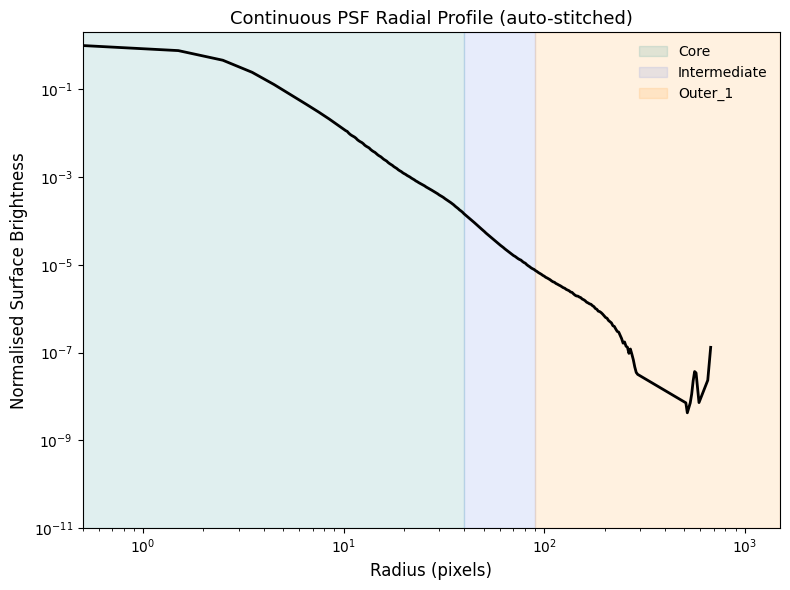

In [14]:
from polaris.radial_profile import build_continuous_profile

r_plot, p_plot, report = build_continuous_profile()